# 04 - Train a CNN on log-Mel spectrogramsThis experiment trains a compact 2D CNN on log-Mel spectrograms. It uses the complete 12-class index from notebook 02, including silence, and the same official train and validation splits as the classical models. The test split is deliberately excluded from training and model selection.The training sampler compensates for class imbalance by sampling classes approximately evenly. This does not change the original validation distribution.

## 1. Imports, paths and reproducibility

In [1]:
from pathlib import Pathimport sys, json, random, timeimport numpy as npimport pandas as pdimport matplotlib.pyplot as pltimport torchfrom sklearn.metrics import ConfusionMatrixDisplayPROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()if str(PROJECT_ROOT) not in sys.path:    sys.path.insert(0, str(PROJECT_ROOT))from src.deep_learning import (    SmallAudioCNN, make_loaders, train_cnn, evaluate_cnn, save_cnn_bundle)DATA_DIR = PROJECT_ROOT / 'notebooks' / 'data' / 'processed'INDEX_PATH = DATA_DIR / 'audio_index_with_silence.csv'MODEL_DIR = PROJECT_ROOT / 'models'MODEL_DIR.mkdir(parents=True, exist_ok=True)if not INDEX_PATH.is_file():    raise FileNotFoundError('Audio index missing. Run notebooks 01 and 02 first.')SEED = 42random.seed(SEED)np.random.seed(SEED)torch.manual_seed(SEED)DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'print('PyTorch:', torch.__version__)print('Device:', DEVICE)print('Index:', INDEX_PATH)

PyTorch: 2.15.0+cpu
Device: cpu
Index: c:\Users\a\Documents\machine_learning_cycle\notebooks\data\processed\audio_index.csv


## 2. Load the split index and create DataLoaders

In [2]:
audio_index = pd.read_csv(INDEX_PATH)
required = {'path', 'target', 'split'}
missing = required.difference(audio_index.columns)
if missing:
    raise ValueError(f'Audio index is missing columns: {sorted(missing)}')
if 'offset_seconds' not in audio_index.columns:
    audio_index['offset_seconds'] = 0.0
print('Rows:', len(audio_index))
display(audio_index.groupby(['split', 'target']).size().unstack(fill_value=0))

BATCH_SIZE = 64
train_loader, validation_loader, labels = make_loaders(
    audio_index, batch_size=BATCH_SIZE, sample_rate=16_000, n_mels=64
)
print('Classes:', labels)
print('Train batches:', len(train_loader), '| Validation batches:', len(validation_loader))

Rows: 105829


target,down,go,left,no,off,on,right,stop,unknown,up,yes
split,,,,,,,,,,,
test,406,402,412,405,402,396,396,411,6931,425,419
train,3134,3106,3037,3130,2970,3086,3019,3111,54074,2948,3228
validation,377,372,352,406,373,363,363,350,6278,350,397


Classes: ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'stop', 'unknown', 'up', 'yes']
Train batches: 1326 | Validation batches: 156


## 3. Inspect one log-Mel batch

Batch shape: (64, 1, 64, 101)
Target shape: (64,)


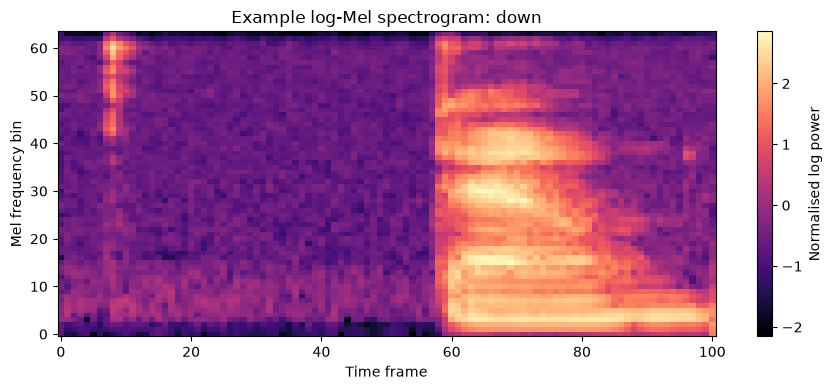

In [3]:
sample_features, sample_targets = next(iter(train_loader))
print('Batch shape:', tuple(sample_features.shape))
print('Target shape:', tuple(sample_targets.shape))
assert sample_features.ndim == 4 and sample_features.shape[1] == 1
assert torch.isfinite(sample_features).all()

plt.figure(figsize=(9, 4))
plt.imshow(sample_features[0, 0].numpy(), origin='lower', aspect='auto', cmap='magma')
plt.title(f'Example log-Mel spectrogram: {labels[int(sample_targets[0])]}')
plt.xlabel('Time frame')
plt.ylabel('Mel frequency bin')
plt.colorbar(label='Normalised log power')
plt.tight_layout()
plt.show()

## 4. Train the CNN

The default run uses the complete training split for six epochs. On a CPU this may take a while because spectrograms are calculated as batches are loaded. The validation split is evaluated after every epoch, and the weights with the best validation macro-F1 are retained.

In [4]:
EPOCHS = 6
LEARNING_RATE = 1e-3
model = SmallAudioCNN(n_classes=len(labels))
parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {parameter_count:,}')
training_started = time.perf_counter()
model, history = train_cnn(
    model, train_loader, validation_loader,
    epochs=EPOCHS, learning_rate=LEARNING_RATE, device=DEVICE
)
total_training_seconds = time.perf_counter() - training_started
print(f'Total training time: {total_training_seconds / 60:.1f} minutes')
display(history.round(4))

Trainable parameters: 156,027
Epoch 01/6 | train loss 0.9759 | val loss 0.8574 | val accuracy 0.6641 | val macro-F1 0.6494 | 1901.3s
Epoch 02/6 | train loss 0.5276 | val loss 0.6320 | val accuracy 0.7610 | val macro-F1 0.7336 | 2366.2s
Epoch 03/6 | train loss 0.4278 | val loss 0.6218 | val accuracy 0.7617 | val macro-F1 0.7305 | 2244.1s
Epoch 04/6 | train loss 0.3627 | val loss 0.5181 | val accuracy 0.7980 | val macro-F1 0.7683 | 1922.4s
Epoch 05/6 | train loss 0.3315 | val loss 0.3990 | val accuracy 0.8530 | val macro-F1 0.8155 | 1621.7s
Epoch 06/6 | train loss 0.3025 | val loss 0.5073 | val accuracy 0.8109 | val macro-F1 0.7757 | 1253.4s
Total training time: 188.6 minutes


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,epoch_seconds
0,1,0.9759,0.6609,0.8574,0.6641,0.6494,1901.3325
1,2,0.5276,0.8211,0.6320,0.7610,0.7336,2366.1768
2,3,0.4278,0.8539,0.6218,0.7617,0.7305,2244.1169
3,4,0.3627,0.8778,0.5181,0.7980,0.7683,1922.4456
4,5,0.3315,0.8880,0.3990,0.8530,0.8155,1621.6694
5,6,0.3025,0.8979,0.5073,0.8109,0.7757,1253.3999


## 5. Training curves

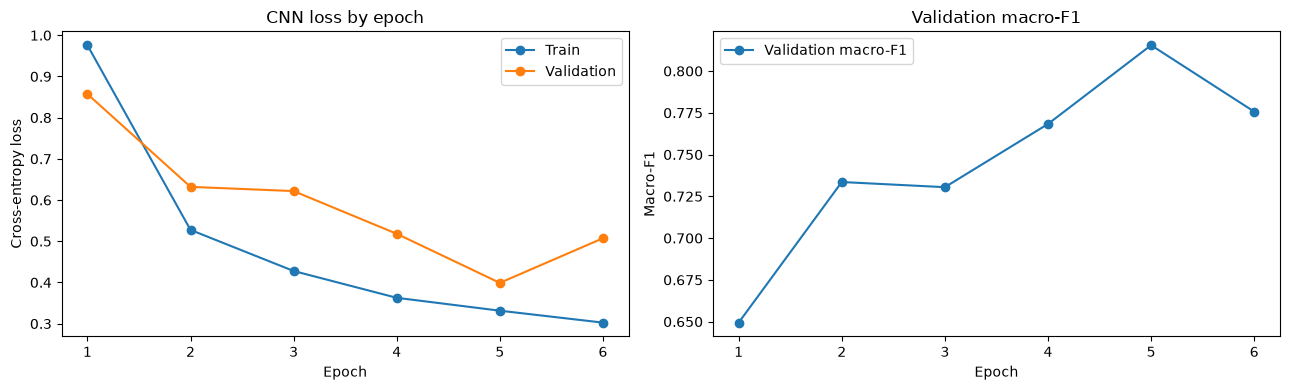

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history['epoch'], history['train_loss'], marker='o', label='Train')
axes[0].plot(history['epoch'], history['validation_loss'], marker='o', label='Validation')
axes[0].set_title('CNN loss by epoch'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-entropy loss'); axes[0].legend()
axes[1].plot(history['epoch'], history['validation_macro_f1'], marker='o', label='Validation macro-F1')
axes[1].set_title('Validation macro-F1'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Macro-F1'); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Evaluate on validation data only

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
small_audio_cnn,0.853,0.9224,0.7413,0.9224,0.8155


,precision,recall,f1-score,support
down,0.758,0.905,0.825,377.000
go,0.592,0.911,0.717,372.000
left,0.774,0.946,0.852,352.000
no,0.681,0.909,0.778,406.000
off,0.768,0.887,0.823,373.000
on,0.591,0.931,0.723,363.000
right,0.700,0.953,0.807,363.000
stop,0.787,0.951,0.862,350.000
unknown,0.993,0.805,0.890,6278.000
up,0.639,0.963,0.769,350.000


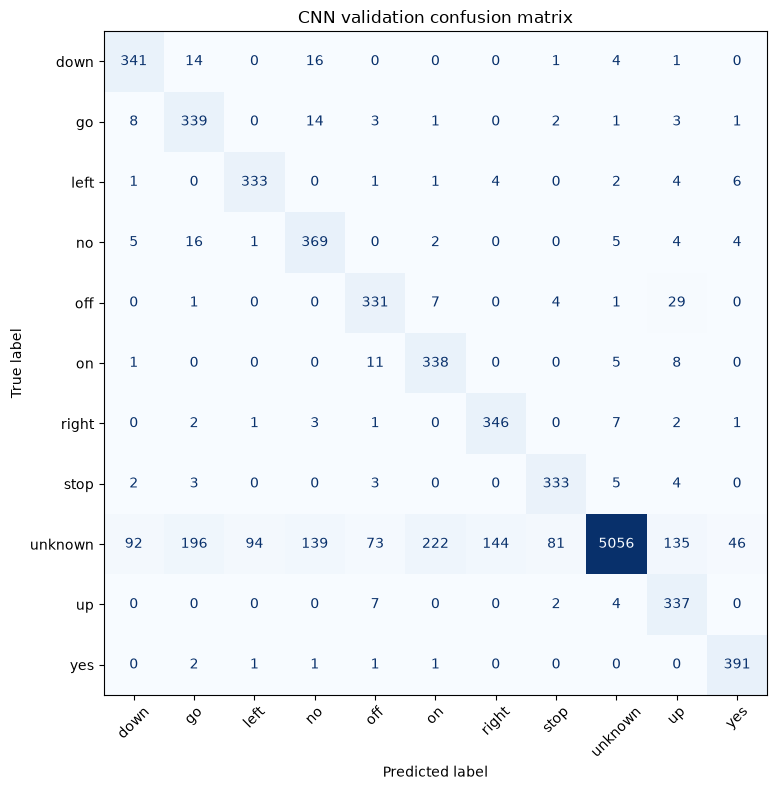

In [6]:
validation_result = evaluate_cnn(model, validation_loader, labels, device=DEVICE)
cnn_metrics = {key: validation_result[key] for key in [
    'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1'
 ]}
display(pd.DataFrame([cnn_metrics], index=['small_audio_cnn']).round(4))
display(pd.DataFrame(validation_result['report']).T.round(3))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=validation_result['confusion_matrix'], display_labels=labels
 ).plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
ax.set_title('CNN validation confusion matrix')
plt.tight_layout(); plt.show()

## 7. Compare with the classical baseline and save the CNN

In [7]:
comparison_rows = [{'model': 'small_audio_cnn', **cnn_metrics}]
classical_metrics_path = MODEL_DIR / 'validation_model_comparison.json'
if classical_metrics_path.is_file():
    classical = pd.read_json(classical_metrics_path)
    for row in classical.to_dict(orient='records'):
        comparison_rows.append(row)
else:
    print('Classical metrics JSON not found; showing CNN metrics only.')
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

checkpoint_path = MODEL_DIR / 'small_audio_cnn.pt'
save_cnn_bundle(model, labels, checkpoint_path, n_mels=64)
history_path = MODEL_DIR / 'cnn_training_history.csv'
history.to_csv(history_path, index=False)
metrics_path = MODEL_DIR / 'cnn_validation_model_comparison.json'
metrics_path.write_text(json.dumps(cnn_metrics, indent=2), encoding='utf-8')
print('Saved CNN checkpoint:', checkpoint_path)
print('Saved training history:', history_path)
print('Saved validation metrics:', metrics_path)
print('\nThe test split remains untouched. Do not report test performance until final model selection.')

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,training_seconds,validation_prediction_seconds
0,small_audio_cnn,0.8530,0.9224,0.7413,0.9224,0.8155,NaN,NaN,NaN
1,linear_svm,0.5132,0.5089,0.3648,0.5089,0.4052,0.5367,23.4196,0.2277
2,random_forest,0.6352,0.1525,0.5341,0.1525,0.1579,0.5006,304.0825,15.2157


Saved CNN checkpoint: c:\Users\a\Documents\machine_learning_cycle\models\small_audio_cnn.pt
Saved training history: c:\Users\a\Documents\machine_learning_cycle\models\cnn_training_history.csv
Saved validation metrics: c:\Users\a\Documents\machine_learning_cycle\models\cnn_validation_model_comparison.json

The test split remains untouched. Do not report test performance until final model selection.


## 8. Interpretation notes

- Compare macro-F1 and balanced accuracy across models because the class distribution is uneven.
- Accuracy alone can hide weak performance on smaller command classes.
- Inspect the confusion matrix to identify commands that the CNN confuses.
- The CNN receives time-frequency patterns, while the SVM and Random Forest receive summary MFCC statistics. The comparison therefore tests two different audio representations as well as different model families.
- The test split remains reserved for the final unbiased evaluation after choosing the model using validation results.